In [1]:
!pip install xgboost 
!pip install lightgbm

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np

In [ ]:
### Read Dataset 
df = pd.read_csv("insurance.csv")
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
### Check dataframe 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [5]:
### Check Columns Summary
df.describe()
"""
Age :- age minumum and maximum is resonable as min is 18 and Max 64
BMI :-  BMI Range	  Category
        < 16	      Severely Underweight
        16 - 18.4	  Underweight
        18.5 - 24.9	  Normal Weight
        25 - 29.9	  Overweight
        30 - 34.9	  Obesity (Class 1)
        35 - 39.9	  Obesity (Class 2)
        ≥ 40	      Morbid Obesity (Class 3)

        
"""

'\nAge :- age minumum and maximum is resonable as min is 18 and Max 64\nBMI :-  BMI Range\t  Category\n        < 16\t      Severely Underweight\n        16 - 18.4\t  Underweight\n        18.5 - 24.9\t  Normal Weight\n        25 - 29.9\t  Overweight\n        30 - 34.9\t  Obesity (Class 1)\n        35 - 39.9\t  Obesity (Class 2)\n        ≥ 40\t      Morbid Obesity (Class 3)\n\n        \n'

In [6]:
### Check for any missing values 
df.isna().sum()
### No Nulls to handle

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [7]:
### Check for outliers 
# for col in df.select_dtypes('number'):
#     sns.boxplot(df[col])
#     plt.show()
### looks like Bmi has outliers 
print(f"Number of outliers {(df[df['bmi']>47]).count()[0]} points")
### As it is only 9 samples & we have no evidence if they are really outliers or rare event we can drop them 


Number of outliers 9 points


C:\Users\AMIT\AppData\Local\Temp\ipykernel_16804\3987616047.py:6: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Number of outliers {(df[df['bmi']>47]).count()[0]} points")


In [8]:
### IQR Remove Function 
def Remove_outlier(col_name):
    """
    This Function is used to remove outliers using IQR 
    args : 
            col_name : col_name to remove outlier from 
    return : Nothing as it inplace function 
    """
    print(f"Data shape before outliers remove {df.shape}")
    # Calculate the upper and lower limits
    Q1 = df[col_name].quantile(0.25)
    Q3 = df[col_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    
    # Create arrays of Boolean values indicating the outlier rows
    upper_array = np.where(df[col_name] >= upper)[0]
    lower_array = np.where(df[col_name] <= lower)[0]
    
    # Removing the outliers
    df.drop(index=upper_array, inplace=True)
    df.drop(index=lower_array, inplace=True)
    print(f"Data shape After outliers remove {df.shape}")



In [9]:
### Removing Outliers
Remove_outlier('bmi')

Data shape before outliers remove (1338, 7)
Data shape After outliers remove (1329, 7)


<Axes: xlabel='charges', ylabel='Count'>

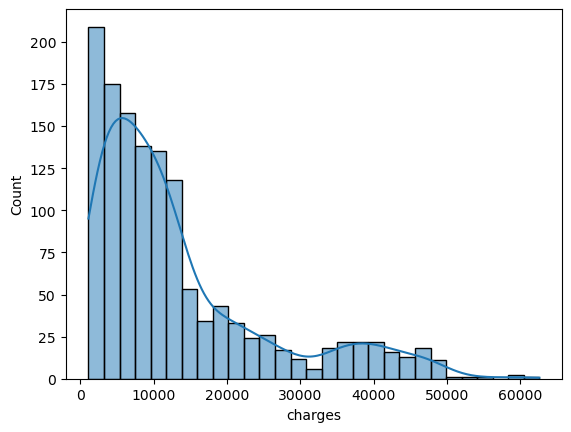

In [10]:
### Visualize Target Distribution 
sns.histplot(data=df, x='charges', kde=True)
### Notes :- Target Variable is Skwed so it will require to transform it using log-transform 

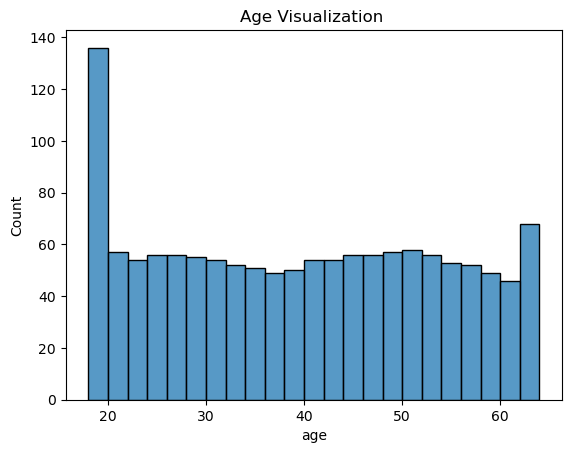

In [11]:
### Visualize Data Distribution
### Data divide into bins each bin equalivant for 2 years
plt.title("Age Visualization ")
sns.histplot(data= df, x="age", bins= 23)
plt.show()

### Note :- alot of data samples are young 

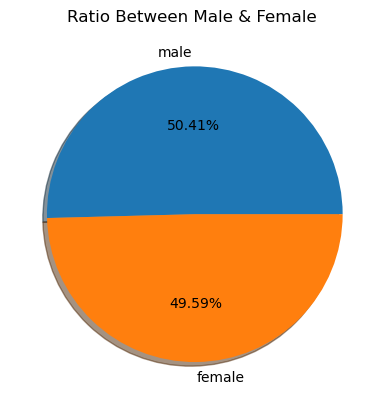

In [12]:
counts = df['sex'].value_counts()

plt.title("Ratio Between Male & Female ")
plt.pie(x = counts.values, labels=counts.index, autopct="%1.2f%%", 
        shadow=True, normalize=True )
plt.show()


In [13]:
### It is better to categorize data 
def Bmi_Categorization(bmi):
    res = None 
    if bmi < 16:
        res = "Severely Underweight"
    elif 16 <= bmi <= 18.4:
        res = "Underweight"
    elif 18.5 <= bmi <= 24.9:
        res = "Normal Weight"
    elif 25 <= bmi <= 29.9:
        res = "Overweight"
    elif 30 <= bmi <= 34.9:
        res = "Obesity (Class 1)"
    elif 35 <= bmi <= 39.9:
        res = "Obesity (Class 2)"
    else:
        res = "Morbid Obesity (Class 3)"
    return res 


df["bmi_category"] = df["bmi"].apply(Bmi_Categorization)

        

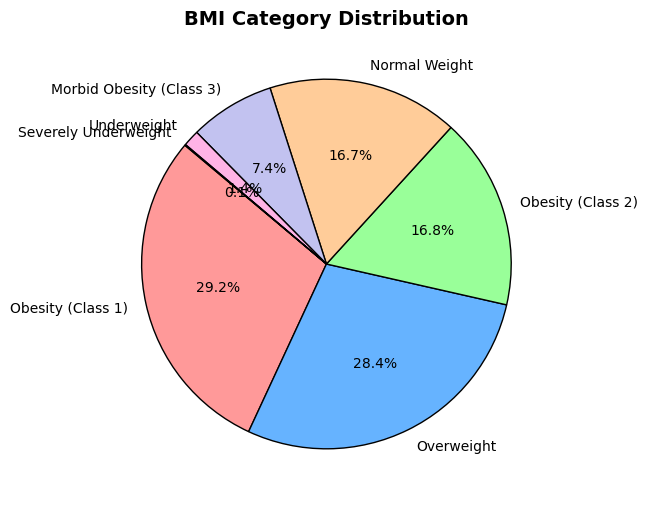

In [14]:
### As number of categories is small we can use Pie chart 
count = df["bmi_category"].value_counts()
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0','#ffb3e6','#c4e17f']
plt.figure(figsize=(6,6))
plt.pie(count.values, labels=count.index, autopct='%1.1f%%', 
        startangle=140, colors=colors, wedgeprops={'edgecolor': 'black'})

plt.title("BMI Category Distribution", fontsize=14, fontweight='bold')
plt.show()

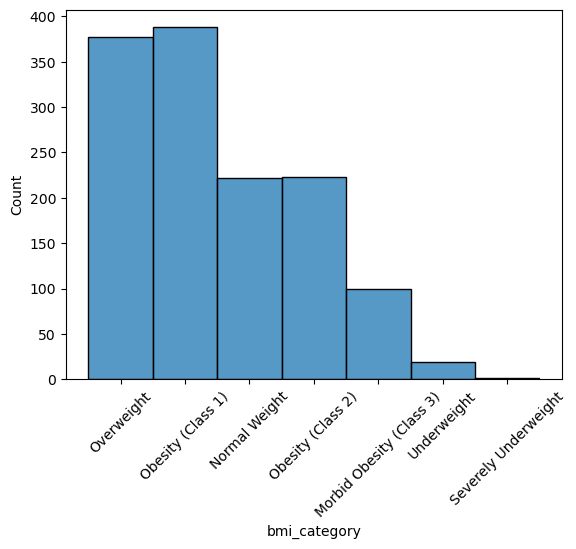

In [15]:
### Better Visualization is barplot 
sns.histplot(data=df.bmi_category)
plt.xticks(rotation=45)
plt.show()
### Note : Looks like overweight is major weight

<Axes: xlabel='children', ylabel='Count'>

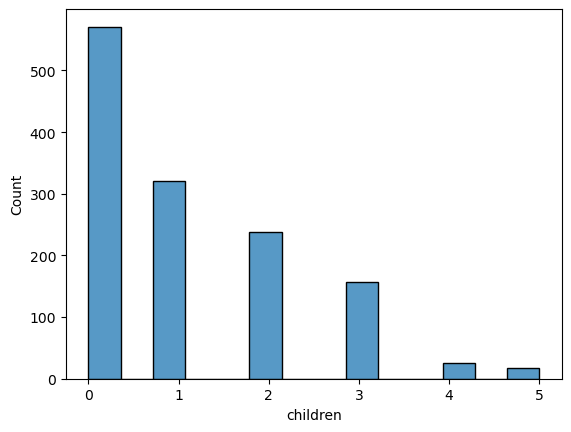

In [16]:
sns.histplot(df.children)
### Note: Looks like Most of people accepted in insurance with no children 

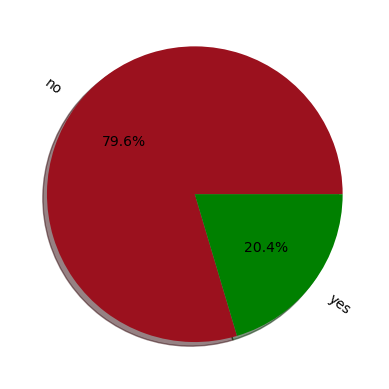

In [17]:
### Smoker 
count = df.smoker.value_counts()
plt.pie(x=count.values, labels=count.index, colors=["#9b111e", "#008000"],
        autopct="%1.1f%%", shadow=True, rotatelabels=True)
plt.show()
### Note: Most of data for Non-smokers 

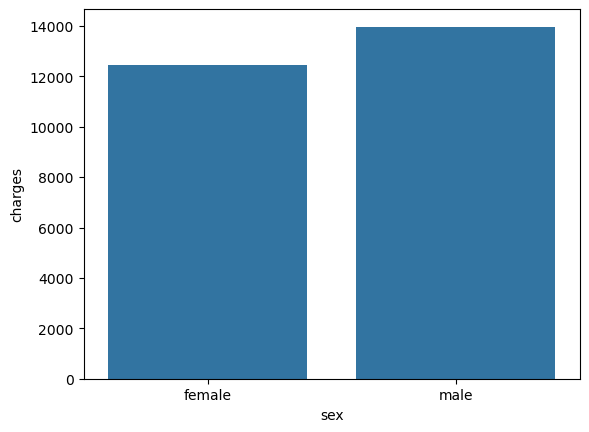

In [18]:
### Does Sex Effect charges ? 
res = df.groupby(["sex"])['charges'].mean()
sns.barplot(res)
plt.show()
### Note :- It doesnot effect 

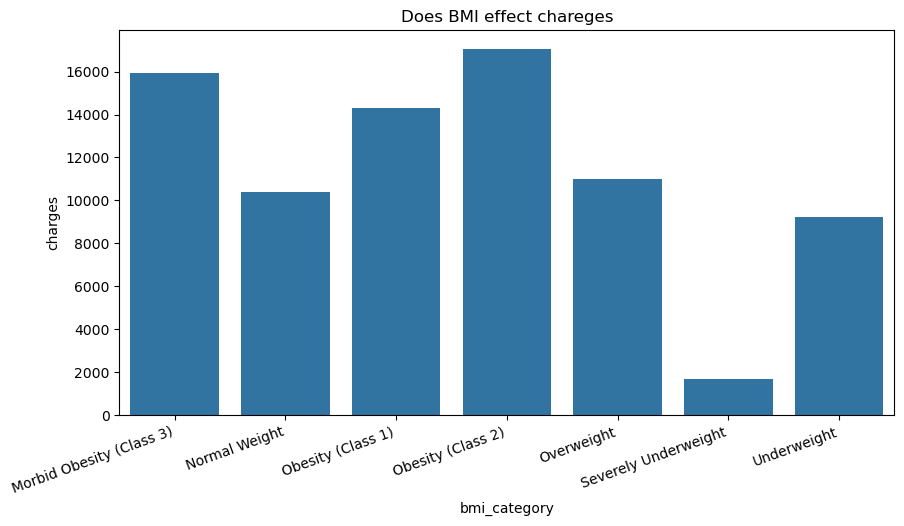

In [19]:
### Does BMI effect chareges 
res = df.groupby(['bmi_category'])['charges'].mean()
plt.figure(figsize=(10,5))
plt.title("Does BMI effect chareges")
sns.barplot(res)
plt.xticks(rotation=20, ha='right')
plt.show()

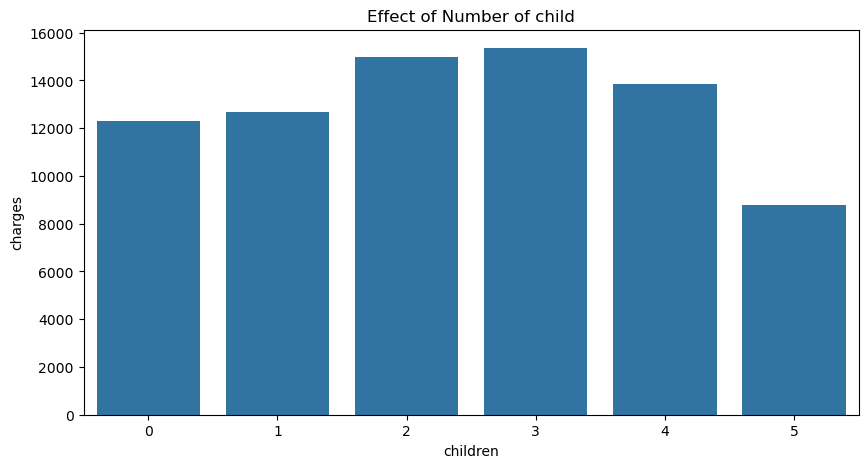

In [20]:
### Does Number of child effect chareges 
res = df.groupby(['children'])['charges'].mean()
plt.figure(figsize=(10,5))
plt.title("Effect of Number of child")
sns.barplot(res)
# plt.xticks(rotation=20, ='right')
plt.show()
### Note:- There is slight effect for people with [2,3,4] child 

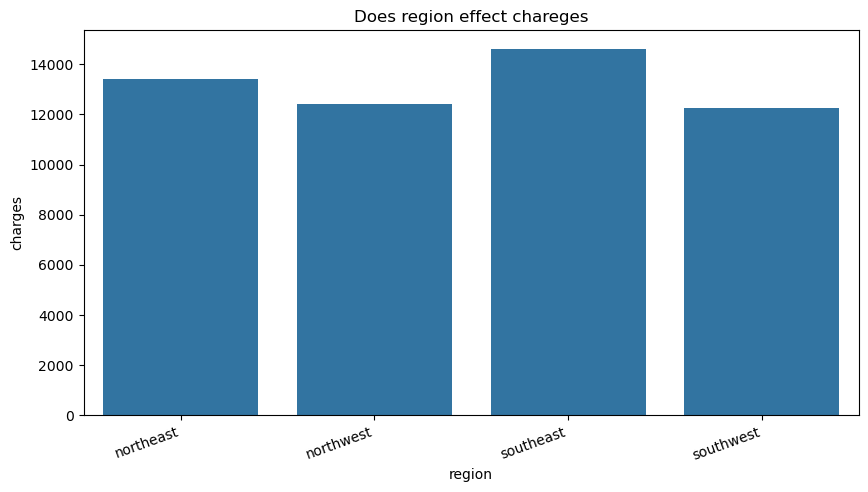

In [21]:
### Does Region affect charges 
res = df.groupby(['region'])['charges'].mean()
plt.figure(figsize=(10,5))
plt.title("Does region effect chareges")
sns.barplot(res)
plt.xticks(rotation=20, ha='right')
plt.show()
### Note : No effect for region on charges

In [22]:
# Function to categorize age
def Age_Categorization(age):

    if 18 <= age <= 24:
        return "Young Adult"
    elif 25 <= age <= 44:
        return "Adult"
    else:
        return "Elder"
 

# Apply the function to create a new age category column
df["age_category"] = df["age"].apply(Age_Categorization)


C:\Users\AMIT\AppData\Local\Temp\ipykernel_16804\3024050349.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="age_category", y="mean", data=res, palette="Blues")


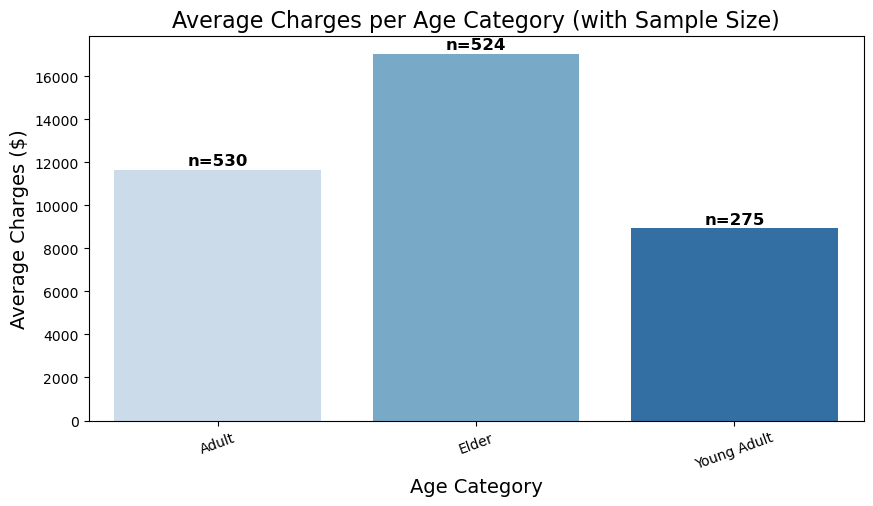

In [23]:
### relation between age & charges 
res = df.groupby("age_category")["charges"].agg(["mean", "count"]).reset_index()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x="age_category", y="mean", data=res, palette="Blues")

for i, row in res.iterrows():
    ax.text(i, row["mean"] + 200, f'n={row["count"]}', ha='center', fontsize=12, fontweight='bold')

# Labels and title
plt.xlabel("Age Category", fontsize=14)
plt.ylabel("Average Charges ($)", fontsize=14)
plt.title("Average Charges per Age Category (with Sample Size)", fontsize=16)
plt.xticks(rotation=20)  # Rotate x-axis labels for better readability
plt.show()


<Axes: >

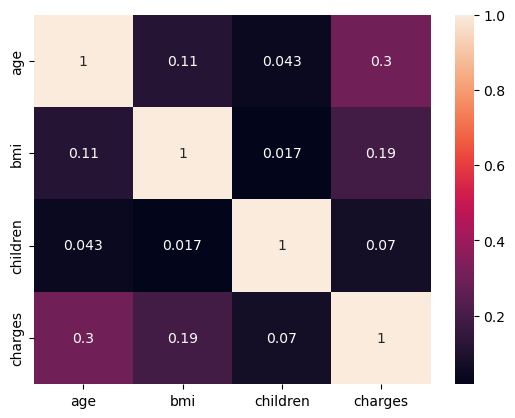

In [24]:
### See correlation between data 
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True)
### Note:- This heatmap shows that we donot have high collerated feature with target 
###        a Good correlation between age & charges which means that older you are the more you will charged
###     

In [25]:
def Convert_to_number(x):
    """
    This Function is to convert smoker column to Numerical
    args   : x is datapoint
    return : equilivant convertion 
    """
    res = None
    if x == "yes":
        res = 1
    else : 
        res = 0 
    return res 


In [26]:
### Scaling Charges columns
df['charges'] = np.log(df['charges'])

In [27]:
### We can try to create features and see if strong relation can be found 
### Try to catch relation between getting older with bmi will increase chance of high risk
df["age_bmi_interaction"] = df["age"] * df["bmi"]
### Try to catch relation if getting older charges increase 
##### df["age_charges_interaction"] = df["age"] * df["charges"] Huge mistake as it causes data leakage
### Try to see if being smoker with same bmi increase rick or not 
df['smoker'] =  df["smoker"].apply(Convert_to_number)
df["smoker_risk"] = df["smoker"]* df["bmi"]

In [28]:
### We have to ask do we have to drop age & bmi after create new feature
### to prevent multicollinearity  or keep them 
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = df[["age", "bmi", "age_bmi_interaction"]]
vif = pd.DataFrame()
vif["Feature"] = features.columns
vif["VIF Score"] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]

print(vif)
### Note:- it show strong collinearity so we have to drop age & bmi 

               Feature  VIF Score
0                  age  29.433008
1                  bmi   9.013253
2  age_bmi_interaction  34.784352


In [29]:
df.drop(['age','bmi'], axis=1, inplace=True)

In [30]:
### Convert Sex column into Number 
def Convert_to_number(x):
    """
    This Function is to convert sex column to Numerical
    args   : x is datapoint
    return : equilivant convertion 
    """
    res = None
    if x == "male":
        res = 1
    else : 
        res = 0 
    return res 
df['sex'] = df['sex'].apply(Convert_to_number)

In [31]:
### split data to Train & test
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop(['charges'], axis=1),
                                                    df['charges'], test_size=.2)

In [32]:
df.columns

Index(['sex', 'children', 'smoker', 'region', 'charges', 'bmi_category',
       'age_category', 'age_bmi_interaction', 'smoker_risk'],
      dtype='object')

In [33]:
from sklearn.preprocessing import StandardScaler
### Scaling columns age_bmi_interaction, age_charges_interaction, smoker_risk
sc = StandardScaler()
columns_to_scale = ['age_bmi_interaction', 'smoker_risk']
x_train[columns_to_scale] = sc.fit_transform(x_train[columns_to_scale].values)
x_test[columns_to_scale] = sc.transform(x_test[columns_to_scale].values)


In [34]:
### Convert Categorical to Numerical 
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder(sparse_output=False, drop='first')
category_col = df.select_dtypes(include='O').columns
x_train_encoded = ohe.fit_transform(x_train[category_col].values)  
x_test_encoded = ohe.transform(x_test[category_col].values)  

x_train_encoded = pd.DataFrame(x_train_encoded, columns=ohe.get_feature_names_out(category_col), index=x_train.index)
x_test_encoded = pd.DataFrame(x_test_encoded, columns=ohe.get_feature_names_out(category_col), index=x_test.index)
x_train = x_train.drop(category_col, axis=1).join(x_train_encoded)
x_test = x_test.drop(category_col, axis=1).join(x_test_encoded)


In [35]:
### Modeling Phase 
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, mean_squared_error, mean_absolute_error, r2_score
import numpy as np
from scipy.stats import uniform, randint

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
import joblib

# Define the pipeline
pipeline = Pipeline([('reg', RandomForestRegressor(random_state=42))])

# Define parameter distributions for different models
parameters = [
    {
        'reg': [RandomForestRegressor(random_state=42)],
        'reg__n_estimators': randint(10, 500),
        'reg__max_depth': [5, 10, 15, 20, 25, 30, None],
        'reg__max_features': ['sqrt', 'log2', None],
        'reg__min_samples_split': randint(2, 20),
        'reg__min_samples_leaf': randint(1, 10),
        'reg__bootstrap': [True, False]
    },
    {
        'reg': [Ridge(random_state=42)],
        'reg__alpha': uniform(0.001, 10.0),
        'reg__solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga'],
        'reg__fit_intercept': [True, False],
    },
    {
        'reg': [Lasso(random_state=42)],
        'reg__alpha': uniform(0.001, 10.0),
        'reg__fit_intercept': [True, False],
        'reg__selection': ['cyclic', 'random']
    },
    {
        'reg': [ElasticNet(random_state=42)],
        'reg__alpha': uniform(0.001, 10.0),
        'reg__l1_ratio': uniform(0.1, 1.0),
        'reg__fit_intercept': [True, False],
        'reg__selection': ['cyclic', 'random']
    },
    {
        'reg': [GradientBoostingRegressor(random_state=42)],
        'reg__learning_rate': uniform(0.001, 0.5),
        'reg__n_estimators': randint(50, 500),
        'reg__subsample': uniform(0.5, 0.9),  
        'reg__max_depth': randint(3, 15),
        'reg__min_samples_split': randint(2, 20),
        'reg__min_samples_leaf': randint(1, 10),
        'reg__max_features': ['sqrt', 'log2', None],
        'reg__loss': ['squared_error', 'absolute_error', 'huber', 'quantile']
    },
    {
        'reg': [DecisionTreeRegressor(random_state=42)],
        'reg__max_depth': [5, 10, 15, 20, 25, 30, None],
        'reg__min_samples_split': randint(2, 20),
        'reg__min_samples_leaf': randint(1, 10),
        'reg__max_features': ['sqrt', 'log2', None],
        'reg__criterion': ['squared_error', 'friedman_mse', 'absolute_error', 'poisson']
    },
    {
        'reg': [XGBRegressor(random_state=42, objective='reg:squarederror')],
        'reg__n_estimators': randint(50, 500),
        'reg__max_depth': randint(3, 40),
        'reg__learning_rate': uniform(0.001, 0.5),
        'reg__subsample': uniform(0.5, 1.0),  
        'reg__colsample_bylevel': uniform(0.3, 0.7),
        'reg__gamma': uniform(0, 5),
        'reg__min_child_weight': randint(1, 10),
        'reg__reg_alpha': uniform(0, 10),
        'reg__reg_lambda': uniform(0, 10),
        'reg__colsample_bytree': uniform(0.3, 1.0),
    },
    {
    'reg': [LGBMRegressor(random_state=42)],
    'reg__n_estimators': randint(50, 500),
    'reg__learning_rate': uniform(0.001, 0.5),
    'reg__colsample_bytree': uniform(0.3, 1.0),  # Keep in range [0,1]
    'reg__min_child_samples': randint(1, 50),
    'reg__reg_alpha': uniform(0, 10),
    'reg__reg_lambda': uniform(0, 10),
    'reg__num_leaves': randint(20, 100),  # Reduce from 150 to prevent overfitting
    'reg__boosting_type': ['gbdt', 'dart'],  # Removed 'goss' to avoid conflicts
    'reg__bagging_fraction': uniform(0.5, 1.0),  # Remove 'subsample'
    },
    {
        'reg': [AdaBoostRegressor(random_state=42)],
        'reg__n_estimators': randint(50, 500),
        'reg__learning_rate': uniform(0.001, 1.0),
        'reg__loss': ['linear', 'square', 'exponential']
    }
]

# Assuming x_train and y_train are already defined
# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    pipeline, 
    parameters, 
    cv=5, 
    n_iter=100, 
    n_jobs=-1, 
    verbose=1, 
    random_state=42,
    scoring='neg_mean_squared_error'  # Added scoring metric
)

# Run the search
random_search.fit(x_train, y_train)

# Best model & parameters
print("Best Model:", random_search.best_estimator_)
print("Best Parameters:", random_search.best_params_)
print("Best Score:", random_search.best_score_)

# # Optional: Save the best model
# joblib.dump(random_search.best_estimator_, 'best_regression_model.pkl')


Fitting 5 folds for each of 100 candidates, totalling 500 fits


C:\Users\AMIT\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
100 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\AMIT\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\AMIT\anaconda3\Lib\site-packages\sklearn\base.py", line 1473, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\AMIT\anaconda3\Lib\site-packages\sklearn\pipeline.py", line 473, in fit
    self._final_estimator.fit(Xt

Best Model: Pipeline(steps=[('reg',
                 GradientBoostingRegressor(learning_rate=0.2262496259847715,
                                           loss='absolute_error', max_depth=6,
                                           max_features='sqrt',
                                           min_samples_leaf=2,
                                           min_samples_split=10,
                                           n_estimators=395, random_state=42,
                                           subsample=0.5879049026057455))])
Best Parameters: {'reg': GradientBoostingRegressor(random_state=42), 'reg__learning_rate': 0.2262496259847715, 'reg__loss': 'absolute_error', 'reg__max_depth': 6, 'reg__max_features': 'sqrt', 'reg__min_samples_leaf': 2, 'reg__min_samples_split': 10, 'reg__n_estimators': 395, 'reg__subsample': 0.5879049026057455}
Best Score: -0.16355613202487446


In [37]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

best_model = random_search.best_estimator_
y_pred = best_model.predict(x_test)
print("R² Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))


R² Score: 0.8412004075652709
MAE: 0.18762108796348334
MSE: 0.14651690756376645


In [38]:
residuals = y_test- y_pred

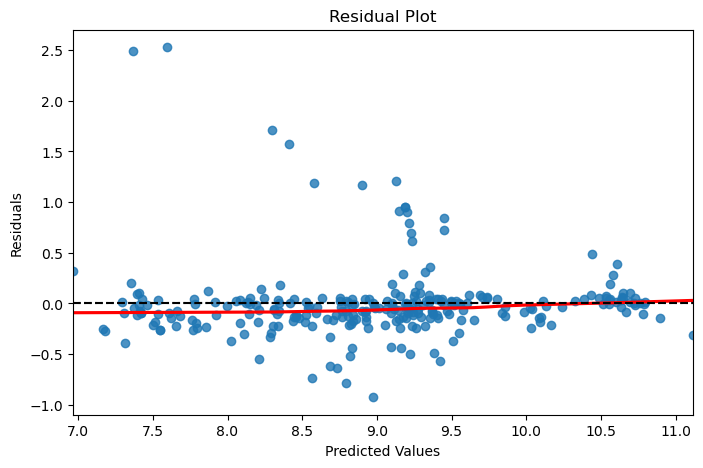

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.residplot(x=y_pred, y=residuals, lowess=True, line_kws={'color': 'red'})
plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


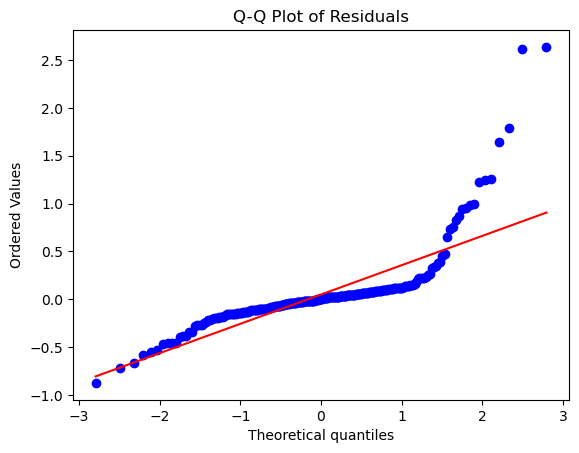

In [40]:
import scipy.stats as stats

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()


### Convert problem to Classification problem 

In [50]:
threhold = y_train.median()
y_class_train = (y_train > threhold).astype(int)
y_class_test  = (y_test > threhold).astype(int)


In [56]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Define the pipeline
pipeline = Pipeline([('clf', RandomForestClassifier(random_state=42))])

# Define parameter distributions for different models
parameters = [
    {
        'clf': [RandomForestClassifier(random_state=42)],
        'clf__n_estimators': randint(10, 500),
        'clf__max_depth': [5, 10, 15, 20, 25, 30, None],
        'clf__max_features': ['sqrt', 'log2', None],
        'clf__min_samples_split': randint(2, 20),
        'clf__min_samples_leaf': randint(1, 10),
        'clf__bootstrap': [True, False]
    },
    {
        'clf': [LogisticRegression(random_state=42, max_iter=500)],
        'clf__C': uniform(0.001, 10.0),
        'clf__solver': ['liblinear', 'lbfgs', 'saga'],
        'clf__fit_intercept': [True, False]
    },
    {
        'clf': [GradientBoostingClassifier(random_state=42)],
        'clf__learning_rate': uniform(0.001, 0.5),
        'clf__n_estimators': randint(50, 500),
        'clf__subsample': np.clip(uniform(0.1, 1.0).rvs(size=10), 0.1, 1.0), 
        'clf__max_depth': randint(3, 15),
        'clf__min_samples_split': randint(2, 20),
        'clf__min_samples_leaf': randint(1, 10),
        'clf__max_features': ['sqrt', 'log2', None]
    },
    {
        'clf': [DecisionTreeClassifier(random_state=42)],
        'clf__max_depth': [5, 10, 15, 20, 25, 30, None],
        'clf__min_samples_split': randint(2, 20),
        'clf__min_samples_leaf': randint(1, 10),
        'clf__max_features': ['sqrt', 'log2', None],
        'clf__criterion': ['gini', 'entropy', 'log_loss']
    },
    {
        'clf': [XGBClassifier(random_state=42, eval_metric='logloss')],
        'clf__n_estimators': randint(50, 500),
        'clf__max_depth': randint(3, 40),
        'clf__learning_rate': uniform(0.001, 0.5),
        'clf__subsample': np.clip(uniform(0.1, 1.0).rvs(size=10), 0.1, 1.0),  
        'clf__colsample_bytree': np.clip(uniform(0.3, 0.9).rvs(size=10), 0.3, 1.0),  
        'clf__colsample_bylevel': np.clip(uniform(0.3, 0.7).rvs(size=10), 0.3, 1.0),
        'clf__gamma': uniform(0, 5),
        'clf__min_child_weight': randint(1, 10),
        'clf__reg_alpha': uniform(0, 10),
        'clf__reg_lambda': uniform(0, 10)
    },
    {
        'clf': [LGBMClassifier(random_state=42)],
        'clf__n_estimators': randint(50, 500),
        'clf__learning_rate': uniform(0.001, 0.5),
        'clf__subsample': np.clip(uniform(0.1, 1.0).rvs(size=10), 0.1, 1.0), 
        'clf__colsample_bytree': np.clip(uniform(0.3, 1.0).rvs(size=10), 0.3, 1.0),  
        'clf__min_child_samples': randint(1, 50),
        'clf__reg_alpha': uniform(0, 10),
        'clf__reg_lambda': uniform(0, 10),
        'clf__num_leaves': randint(20, 150),
        'clf__boosting_type': ['gbdt', 'dart', 'goss'],
        'clf__bagging_fraction': [0.6, 0.7, 0.8, 0.9, 1.0]
    },
    {
        'clf': [AdaBoostClassifier(random_state=42)],
        'clf__n_estimators': randint(50, 500),
        'clf__learning_rate': uniform(0.001, 1.0)
    }
]

# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    pipeline, 
    parameters, 
    cv=5, 
    n_iter=100, 
    n_jobs=-1, 
    verbose=1, 
    random_state=42,
    scoring='accuracy'  
)

# Run the search
random_search.fit(x_train, y_class_train)

# Best model & parameters
print("Best Model:", random_search.best_estimator_)
print("Best Parameters:", random_search.best_params_)
print("Best Score:", random_search.best_score_)


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Model: Pipeline(steps=[('clf',
                 RandomForestClassifier(bootstrap=False, max_depth=20,
                                        min_samples_leaf=2, n_estimators=313,
                                        random_state=42))])
Best Parameters: {'clf': RandomForestClassifier(random_state=42), 'clf__bootstrap': False, 'clf__max_depth': 20, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__min_samples_split': 2, 'clf__n_estimators': 313}
Best Score: 0.9162591903622996


In [57]:
# Optional: Evaluate on test set if available
from sklearn.metrics import classification_report, confusion_matrix
y_pred = random_search.best_estimator_.predict(x_test)
print(classification_report(y_class_test, y_pred))
print(confusion_matrix(y_class_test, y_pred))

# Optional: Save the best model
# import joblib
# joblib.dump(random_search.best_estimator_, 'best_classification_model.pkl')

              precision    recall  f1-score   support

           0       0.90      0.95      0.93       133
           1       0.95      0.89      0.92       133

    accuracy                           0.92       266
   macro avg       0.93      0.92      0.92       266
weighted avg       0.93      0.92      0.92       266

[[127   6]
 [ 14 119]]
